## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [1]:
#Import packages
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
# import dataset
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [31]:
df.head(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [43]:
print(f"Dataset contains {df.shape[0]} rows and {df.shape[1]} columns")
print(df.describe())
print(df.info())

Dataset contains 2443651 rows and 9 columns
                uid         stars       reviews         price  \
count  2.443651e+06  2.443651e+06  2.443651e+06  2.443651e+06   
mean   1.370545e+06  2.152836e+00  4.806278e+02  8.924381e+01   
std    8.160562e+05  2.194865e+00  5.944124e+03  3.456089e+02   
min    1.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00   
25%    6.589215e+05  0.000000e+00  0.000000e+00  9.990000e+00   
50%    1.349029e+06  0.000000e+00  0.000000e+00  1.909000e+01   
75%    2.060686e+06  4.400000e+00  5.900000e+01  4.599000e+01   
max    2.828593e+06  5.000000e+00  1.356658e+06  1.000000e+05   

       boughtInLastMonth  
count       2.443651e+06  
mean        2.589699e+01  
std         2.404837e+02  
min         0.000000e+00  
25%         0.000000e+00  
50%         0.000000e+00  
75%         0.000000e+00  
max         5.000000e+04  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column    

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:

   - Generate a frequency table for the product `category`.
   - Which are the top 5 most listed product categories?
2. **Visualizations**:

   - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
   - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [7]:
# Create the frequeancy table for caetgory 
frecuency_table = df['category'].value_counts().sort_values(ascending=False)
print(f"{frecuency_table}\n")

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64



In [10]:
short_labels = {
    "Handmade Clothing, Shoes & Accessories": "Handmade clothing and shoes",
    "Sports & Outdoors": "Sports",
    "Beauty": "Beauty",
    "Birthday Gifts":"Gifts",
    "Bath & Body": "Bath"
}

C:\Users\franc\AppData\Local\Temp\ipykernel_23312\1559627826.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_5.index,  y=top_5.values, palette='Set2')


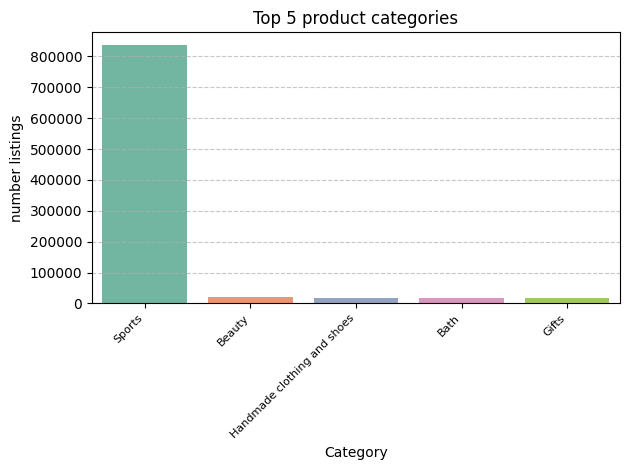

In [ ]:
# Takes the top 5 categories
top_5 = frecuency_table.head(5)
# Replace long category names with shorter ones
top_5.index = top_5.index.map(lambda x: short_labels.get(x, x))
# Create the bar plot 
sns.barplot(x=top_5.index,  y=top_5.values, palette='Set2')
plt.title('Top 5 product categories')
plt.xlabel('Category')
plt.ylabel('number listings')
plt.xticks(rotation=45,ha='right', fontsize=8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

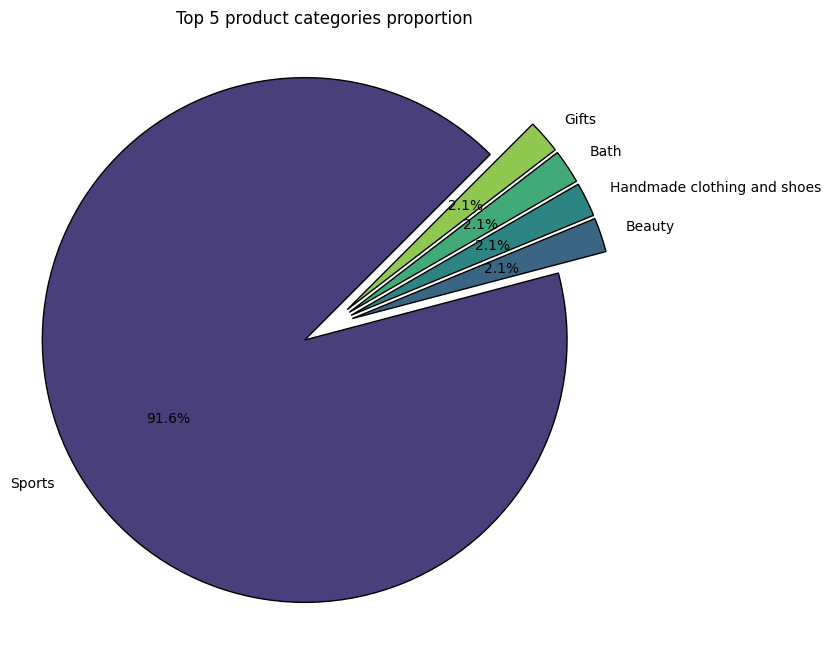

In [ ]:
#Pie Chart 
plt.figure(figsize=(8,8))
plt.pie(
    top_5.values, 
    labels=top_5.index,
    autopct='%1.1f%%',
    startangle=45,
    colors=sns.color_palette('viridis', n_colors=len(top_5), desat=0.8),
    explode=(0.1, 0.1, 0.1, 0.1, 0.1),  # Slightly separate the slices
    wedgeprops={'edgecolor': 'black', 'linewidth': 1}
)
plt.title('Top 5 product categories proportion')
plt.axis('equal')
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:

   - Calculate the mean, median, and mode for the `price` of products.
   - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [47]:
# mean, median and mode of price 
mean__price = round(df['price'].mean(), 2)
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print(f"Mean price: {mean__price}")
print(f"Median price: {median_price}")
print(f"Mode price: {mode_price}")

Mean price: 89.24
Median price: 19.09
Mode price: 9.99


2. **Measures of Dispersion**:

   - Determine the variance, standard deviation, range, and interquartile range for product `price`.
   - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [51]:
#Determine the variance, standard deviation, range, and interquartile range for product `price`.
variance_price = round(df['price'].var(),2)
std_dev_price = round(df['price'].std(),2)
price_range = round(df['price'].max()-df['price'].min(),2)
iqr= df ['price'].quantile(0.75)-df ['price'].quantile(0.25) 
iqr_price = round(iqr, 2)

print(
    f"Variance of price: {variance_price}\n"
    f"Standard deviation of price: {std_dev_price}\n"
    f"Range of price: {price_range}\n"
    f"Interquartile range of price: {iqr_price}\n"
    f"Minimum price: {df['price'].min()}\n"
    f"Maximum price: {df['price'].max()}\n\n"
    f"Conclusión:\n"
    f"La variabilidad de los precios en el dataset es considerable.\n"
    f"- Media: {mean__price}\n"
    f"- Mediana: {median_price}\n"
    f"- Moda: {mode_price}\n"
    f"- Desviación estándar: {std_dev_price}\n"
    f"- IQR: {iqr_price}\n"
    f"- Rango: {price_range}\n\n"
    f"Esto indica que los precios de los productos son muy diversos, con algunos productos significativamente más caros que otros (precio máximo: {df['price'].max()}, mínimo: {df['price'].min()})."
)


Variance of price: 119445.49
Standard deviation of price: 345.61
Range of price: 100000.0
Interquartile range of price: 36.0
Minimum price: 0.0
Maximum price: 100000.0

Conclusión:
La variabilidad de los precios en el dataset es considerable.
- Media: 89.24
- Mediana: 19.09
- Moda: 9.99
- Desviación estándar: 345.61
- IQR: 36.0
- Rango: 100000.0

Esto indica que los precios de los productos son muy diversos, con algunos productos significativamente más caros que otros (precio máximo: 100000.0, mínimo: 0.0).


3. **Visualizations**:

   - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
   - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing

In [55]:
skewness_price = round(df['price'].skew(),2)
kurtosis_price = round(df['price'].kurtosis(),2)

print(
    f"Skewness of price: {skewness_price}\n"
    f"Kurtosis of price: {kurtosis_price}\n\n"
    f"Conclusión:\n"
    f"La distribución de los precios es {'asimétrica a la derecha' if skewness_price > 0 else 'asimétrica a la izquierda' if skewness_price < 0 else 'simétrica'}.\n"
    f"La kurtosis indica que la distribución es {'plana' if kurtosis_price < 0 else 'picuda' if kurtosis_price > 0 else 'normal'}."
)


Skewness of price: 27.49
Kurtosis of price: 4241.62

Conclusión:
La distribución de los precios es asimétrica a la derecha.
La kurtosis indica que la distribución es picuda.


95th percentile of price: 349.515
(2321449, 9)


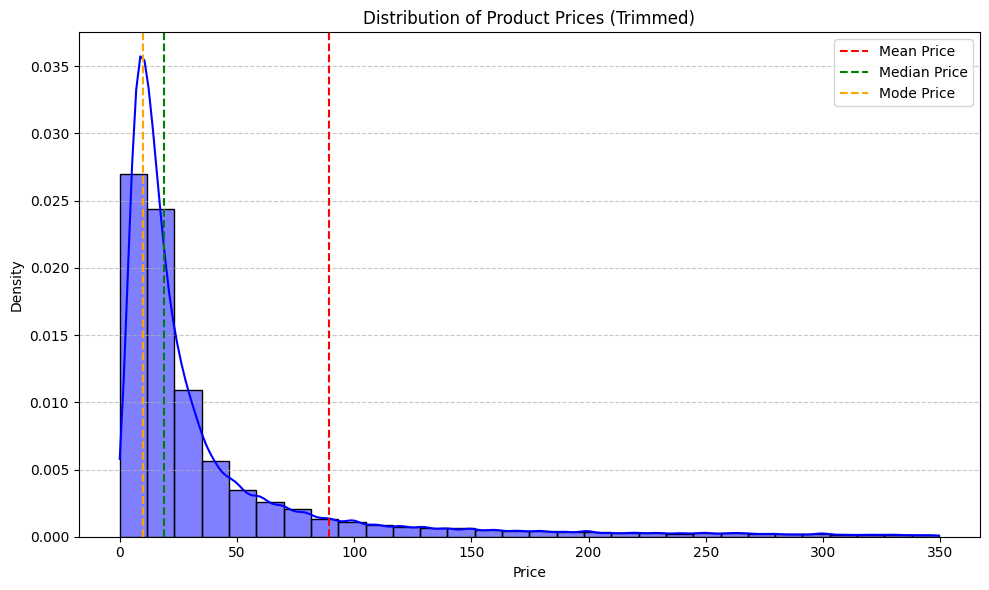

In [ ]:
df = df[df['price'].notnull()& df['price']>0]

p95 =np.percentile(df['price'], 95)
print(f"95th percentile of price: {p95}")
df_trimmed = df[df['price'] <= p95]
print(df_trimmed.shape)

#histogram of df_trimmed['price']

plt.figure(figsize=(10, 6))
sns.histplot(df_trimmed['price'], bins=30, kde=True, color='blue', stat='density')
plt.title('Distribution of Product Prices (Trimmed)')
plt.xlabel('Price')
plt.ylabel('Density')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.axvline(mean__price, color='red', linestyle='--', label='Mean Price')
plt.axvline(median_price, color='green', linestyle='--', label='Median Price')
plt.axvline(mode_price, color='orange', linestyle='--', label='Mode Price')
plt.legend()
plt.tight_layout()
plt.show()

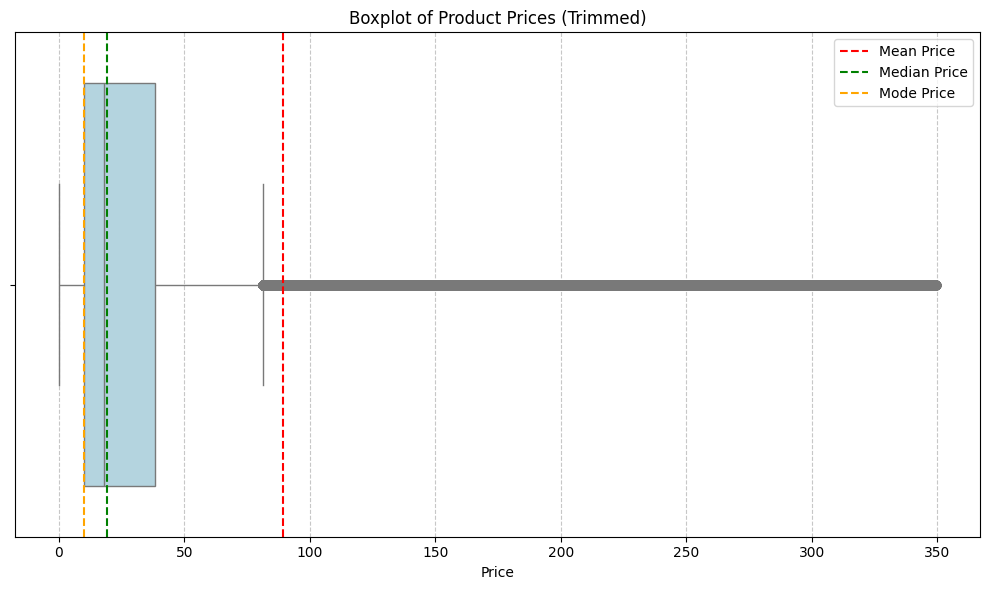

In [59]:
#boxplot of df_trimmed['price']
plt.figure(figsize=(10, 6))
sns.boxplot(x=df_trimmed['price'], color='lightblue')
plt.title('Boxplot of Product Prices (Trimmed)')
plt.xlabel('Price')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.axvline(mean__price, color='red', linestyle='--', label='Mean Price')
plt.axvline(median_price, color='green', linestyle='--', label='Median Price')
plt.axvline(mode_price, color='orange', linestyle='--', label='Mode Price')
plt.legend()
plt.tight_layout()
plt.show()


### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

**1.Measures of Centrality**:

- Calculate the mean, median, and mode for the `rating` of products.
- How do customers generally rate products? Is there a common trend?

In [63]:
pd.set_option("display.float_format", "{:.2f}".format)
print(df['stars'].describe())

pd.reset_option("display.float_format")

count   2443631.00
mean          2.15
std           2.19
min           0.00
25%           0.00
50%           0.00
75%           4.40
max           5.00
Name: stars, dtype: float64


**2.Measures of Dispersion**:

- Determine the variance, standard deviation, and interquartile range for product `rating`.
- Are the ratings consistent, or is there a wide variation in customer feedback?

In [ ]:
mode = df['stars'].mode()[0]
variance = df['stars'].var()
min_price = df['stars'].min()
max_price = df['stars'].max()
range_price = max_price - min_price
iqr= df ['stars'].quantile(0.75)-df ['stars'].quantile(0.25) #rango intercuartil, contiene el 50% de los datos.
print (f"""Mode:{mode},
    Variance: {variance}
    Range: {range_price}
    IQR:{iqr}
        """)
print(
"""- La media es baja
- La mediana y la moda es 0 porque muchos productos no tienen clasificación 
- La varianza es 4 y pico, mucha dispersión enlas calificaciones
- El rango es 5, por lo que las calificaciones abarcan ese rango 
- El IQR indica que la mayoría de calificaciones se agrupan entre el 0 y 4,4.""" )

Mode:0.0,
       Variance: 4.817425709696724
       Range: 5.0
       IQR:4.4
        
- La media es baja
- La mediana y la moda es 0 porque muchos productos no tienen clasificación 
- La varianza es 4 y pico, mucha dispersión enlas calificaciones
- El rango es 5, por lo que las calificaciones abarcan ese rango 
- El IQR indica que la mayoría de calificaciones se agrupan entre el 0 y 4,4.


**4.Shape of the Distribution**:

- Calculate the skewness and kurtosis for the `rating` column.
- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [67]:
skewness_rating = round(df['stars'].skew(),2)
kurtosis_rating = round(df['stars'].kurtosis(),2)

print( f"La distribución de los precios es {'asimétrica a la derecha' if skewness_rating > 0 else 'asimétrica a la izquierda' if skewness_rating < 0 else 'simétrica'}.\n"
    f"La kurtosis indica que la distribución es {'plana' if kurtosis_rating < 0 else 'picuda' if kurtosis_rating > 0 else 'normal'}.")


La distribución de los precios es asimétrica a la derecha.
La kurtosis indica que la distribución es plana.


**5.Visualizations**:

- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

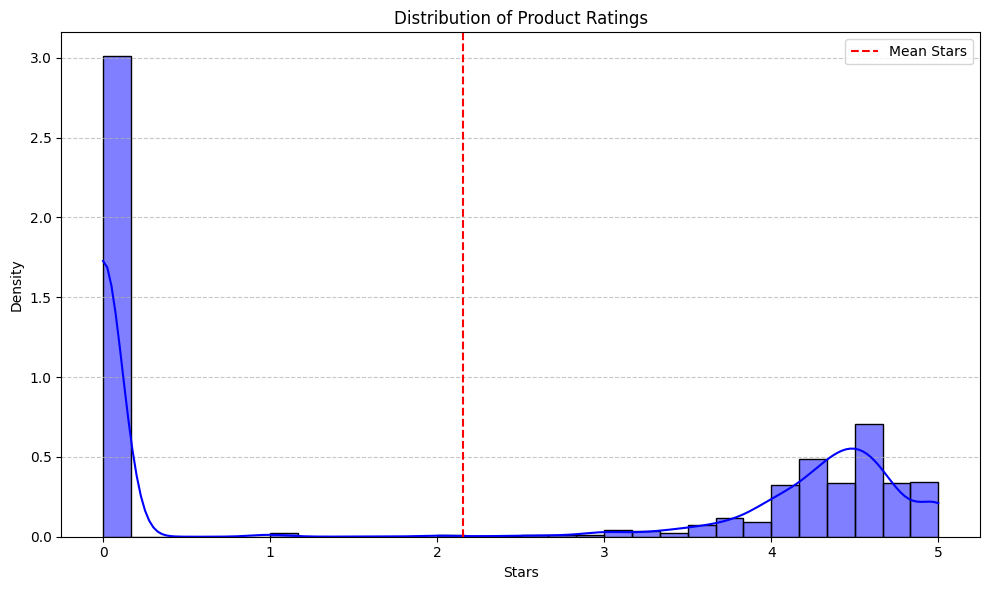

In [69]:
#histogram
plt.figure(figsize=(10, 6))
sns.histplot(df['stars'], bins=30, kde=True, color='blue', stat='density')
plt.title('Distribution of Product Ratings')
plt.xlabel('Stars')
plt.ylabel('Density')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.axvline(df['stars'].mean(), color='red', linestyle='--', label='Mean Stars')
plt.legend()
plt.tight_layout()
plt.show()